# 2 · Chapter 4 (4.2–4.4, 4.8): degrees of freedom, reference frames, main-frame position

Code: `okane/frames.py`, `okane/params.py`, `okane/kinematics.py` (numeric) and `okane/symbolic.py` (SymPy derivation + code generation).

> **Parameters.** The thesis does not list the geometry or inertia of the test bike (2004 CBR600RR).
> `cbr600rr_estimate()` builds a plausible set from public data (wheelbase 1.390 m, rake 24°, trail 95 mm) and the few numbers in the text
> (270 kg, tyre radii and profile points of Section 5.5). Everything flagged *estimate* in `params.py` should be replaced by measurements.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))   # repo root (not needed after `pip install -e .`)
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from okane import frames, symbolic
from okane.params import cbr600rr_estimate
from okane.kinematics import Kinematics, make_q
from okane.plotting import use_style, side_view, C
use_style()
p, design = cbr600rr_estimate()
kin = Kinematics(p)
deg = np.degrees

## 4.2 Degrees of freedom (Gruebler)
Seven bodies including the ground *N*: main frame *A*, swing-arm *B*, fork lower *C*, rear wheel *D*, steering assembly *F*, front wheel *G*.
Joints *G–C*, *D–B*, *F–A*, *B–A* are revolute, *C–F* is prismatic (5 constraints each); the wheel–ground "joints" are unconstrained because the
tyres are compliant (Table 4.2).

In [2]:
bodies, constraints = 7, {"N-G": 0, "N-D": 0, "G-C": 5, "D-B": 5, "C-F": 5, "F-A": 5, "B-A": 5}
print("d.o.f. =", 6 * (bodies - 1) - sum(constraints.values()))

d.o.f. = 11


## 4.3 Generalised co-ordinates (Table 4.3)
| | | | |
|---|---|---|---|
| $q_1$ fork extension (0 = bottomed) | $q_2$ swing-arm angle rel. to frame | $q_3,q_4$ front / rear tyre deflection | $q_5,q_6$ wheel rotation |
| $q_7,q_8$ position on the ground ($\hat n_1,\hat n_3$) | $q_9=\gamma$ roll | $q_{10}=\psi$ yaw | $q_{11}=\delta$ steer |

Axis convention (Figs. 4.4/4.5): **1 forward, 2 up, 3 to the right**. Hence yaw and steer are positive to the *left*, roll is positive to the *right*,
pitch $\mu$ positive nose-up, and a wheel rolling forward has a *negative* spin rate.

## 4.4 Reference frames (Table 4.4)
`frames.chain` builds the direction-cosine matrices; the rows of each matrix below are the child unit vectors in the parent basis, exactly as printed in Table 4.4.

In [3]:
q9, q10, q11, q2, mu, eps = sp.symbols("q9 q10 q11 q2 mu epsilon")
show = {"M from N": frames.Ry(q10, sp).T, "D from M": frames.Rx(q9, sp).T, "A from D": frames.Rz(mu, sp).T,
        "B from A": frames.Rz(q2, sp).T, "E from A": frames.Rz(eps, sp).T, "F from E": frames.Ry(q11, sp).T}
for name, M in show.items():
    print(name); display(M)

M from N


Matrix([
[cos(q10), 0, -sin(q10)],
[       0, 1,         0],
[sin(q10), 0,  cos(q10)]])

D from M


Matrix([
[1,        0,       0],
[0,  cos(q9), sin(q9)],
[0, -sin(q9), cos(q9)]])

A from D


Matrix([
[ cos(mu), sin(mu), 0],
[-sin(mu), cos(mu), 0],
[       0,       0, 1]])

... (2 outputs left out)

E from A


Matrix([
[ cos(epsilon), sin(epsilon), 0],
[-sin(epsilon), cos(epsilon), 0],
[            0,            0, 1]])

F from E


Matrix([
[cos(q11), 0, -sin(q11)],
[       0, 1,         0],
[sin(q11), 0,  cos(q11)]])

### The model in its design configuration
Key points of Table 4.1 / Fig. 4.2, drawn from the kinematics code.

wheelbase 1.3900 m   trail 95.0 mm   normal trail 86.8 mm   pitch 3.99e-17 rad
mass centre (x from rear contact, height): [0.7121 0.6155]  total mass 270.0


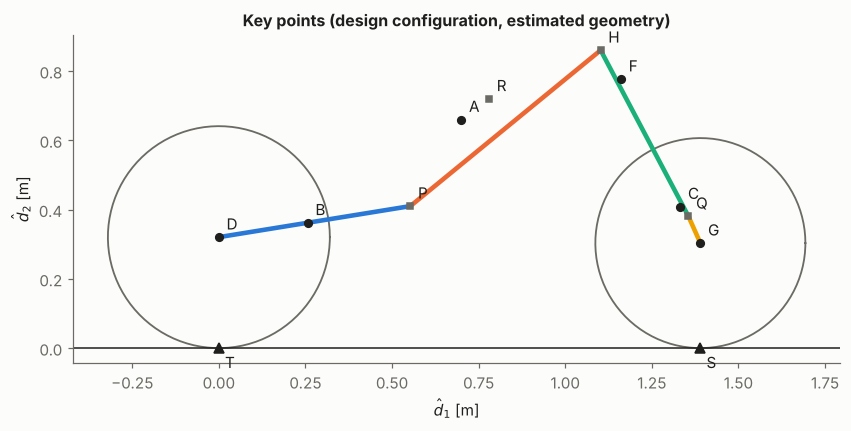

In [4]:
q0 = make_q(q1=design["q1"], q2=design["q2"])
k0 = kin.config(q0)
side_view(kin, k0); plt.title("Key points (design configuration, estimated geometry)")
print(f"wheelbase {k0['wheelbase']:.4f} m   trail {k0['trail']*1e3:.1f} mm   normal trail {k0['normal_trail']*1e3:.1f} mm   pitch {k0['mu']:.2e} rad")
print("mass centre (x from rear contact, height):", kin.mass_centre(k0)[:2].round(4), " total mass", p.total_mass)

### 4.4.2 / 4.4.3  Front wheel frames: $\xi$, camber $\gamma_1$, kinematic steering angle $\delta'$
`frames.front_wheel_frames` constructs *G* ($\hat g_1$ horizontal, $\hat g_3$ = axle) and *H* ($\hat h_2$ vertical) exactly from cross products.
The thesis' closed forms for $\gamma_1$ and $\delta'$ (below eq. 4.1) are exact; $\xi=\varepsilon+\mu$ only holds for small steering angles.

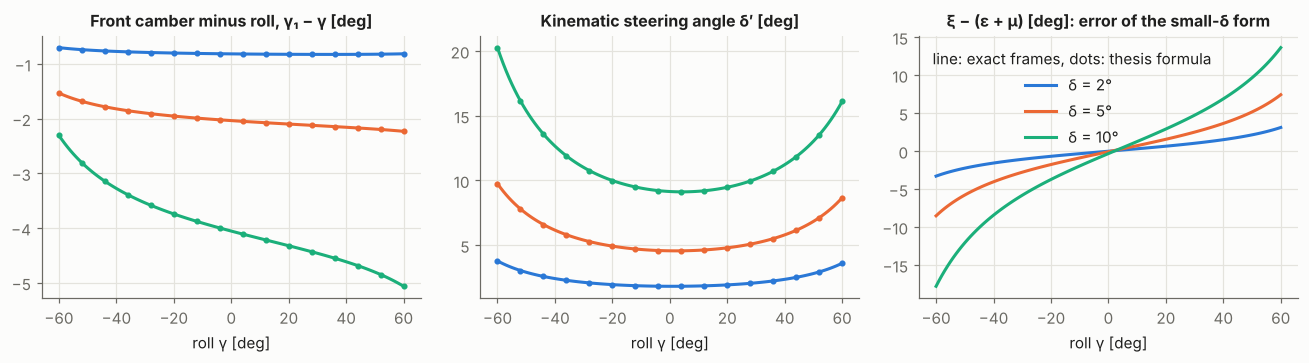

In [5]:
roll = np.radians(np.linspace(-60, 60, 121))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for i, st in enumerate([2.0, 5.0, 10.0]):
    g1, dk, xi, g1t, dkt, mus = [], [], [], [], [], []
    for r in roll:
        k = kin.config(make_q(q1=0.08, q2=0.15, q9=r, q11=np.radians(st)))
        g1.append(k["gamma1"]); dk.append(k["delta_k"]); xi.append(k["xi"]); mus.append(k["mu"])
        g1t.append(frames.camber_thesis(r, np.radians(st), p.eps, k["mu"]))
        dkt.append(frames.kin_steer_thesis(r, np.radians(st), p.eps, k["mu"]))
    ax[0].plot(deg(roll), deg(np.array(g1)) - deg(roll), color=C[i], label=f"δ = {st:.0f}°")
    ax[0].plot(deg(roll)[::8], (deg(np.array(g1t)) - deg(roll))[::8], "o", color=C[i], ms=3)
    ax[1].plot(deg(roll), deg(dk), color=C[i]); ax[1].plot(deg(roll)[::8], deg(dkt)[::8], "o", color=C[i], ms=3)
    ax[2].plot(deg(roll), deg(np.array(xi) - (p.eps + np.array(mus))), color=C[i])
ax[0].set_title("Front camber minus roll, γ₁ − γ [deg]"); ax[1].set_title("Kinematic steering angle δ′ [deg]")
ax[2].set_title("ξ − (ε + μ) [deg]: error of the small-δ form")
for a in ax: a.set_xlabel("roll γ [deg]")
ax[2].legend(*ax[0].get_legend_handles_labels(), title="line: exact frames, dots: thesis formula", loc="upper left")
plt.tight_layout()

## 4.8 Main-frame position
The vector loop (4.12) from the rear tyre point to the front tyre point
$$T'_{Rz}\hat d_2+R_a\hat b_1+(P_x+H_x)\hat a_1+(P_z+H_z)\hat a_2+Q_x\hat f_1+(Q_z-q_1)\hat f_2-T'_{Fz}\hat g_2$$
must close on the ground. This fixes the pitch angle $\mu=q_{14}$, which is *not* a generalised co-ordinate.

**Tyre profile.** $T_y(\gamma),T_z(\gamma)$ are the contact-point co-ordinates in the wheel frame. Until Chapter 5 a toroidal profile is used,
$T_z=R-\rho+\rho\cos\gamma$, $T_y=\rho\sin\gamma$, with crown radii from a circle through the measured tread edge and crown of Table 5.6
(front 60.5 mm, rear 103.6 mm). Then (4.13) becomes $T'_z=R-\rho+(\rho-q)/\cos\gamma$.

Two solutions are implemented:
* **exact** – `Kinematics.mu_exact`: Newton iteration on "lowest point of the front tyre is $q_3$ below the ground" with the true front camber;
* **thesis** – eq. (4.17): $\gamma_1\approx q_9$, $\tan^2\delta\approx0$, $\sin\mu\approx\mu$.

### 4.8.1 Check of the printed coefficients $H,H_1,\dots,H_{11}$ (p. 73)
`symbolic.thesis_pose` holds (4.17) in SymPy; its gradient at $q_3=q_4=0$ must equal the printed expressions.

In [6]:
qc = make_q(q1=0.07, q2=0.12, q9=np.radians(60), q11=np.radians(10))
H_sym = kin.pitch(qc, model="thesis")[1]
pr = kin.H_printed(qc)
print(f"{'':5s}{'printed p.73':>14s}{'d(4.17)/dq':>14s}{'exact loop':>14s}")
H_ex = kin.pitch(qc, model="exact")[1]
for name, i in [("H1", 0), ("H2", 1), ("H3", 2), ("H4", 3), ("H9", 8), ("H11", 10)]:
    print(f"{name:5s}{pr[name]:14.6f}{H_sym[i]:14.6f}{H_ex[i]:14.6f}")
print(f"W0 = {pr['W0']:.4f} m,  mu: (4.17) {kin.mu_thesis(qc):.5f}  exact {kin.mu_exact(qc):.5f} rad")

       printed p.73    d(4.17)/dq    exact loop
H1         0.666037      0.666037      0.687965
H2        -0.402152     -0.402152     -0.417858
H3        -1.442399     -1.442399     -1.502079
H4         1.442399      1.442399      1.502079
H9        -0.107580     -0.107580     -0.054511
H11        0.001759      0.001759      0.135488
W0 = 1.3866 m,  mu: (4.17) -0.02450  exact -0.00612 rad


The printed coefficients are the exact gradient of (4.17). Against the exact loop closure they agree for $q_1\dots q_4$ within a few percent,
but **$H_{11}$ (pitch per steering angle) is two orders of magnitude too small at 60° roll**: with the bike leaned, steering moves the front
contact point around the tyre and raises/lowers the front, an effect removed by $\gamma_1\approx q_9$.

### Fig. 4.27 revisited: pitch angle, exact vs. (4.17) vs. linearised (4.18)
As in the thesis: 60° roll, 10° steer, 5 mm tyre deflections, one co-ordinate swept at a time; the linearisation point is the middle of each range.

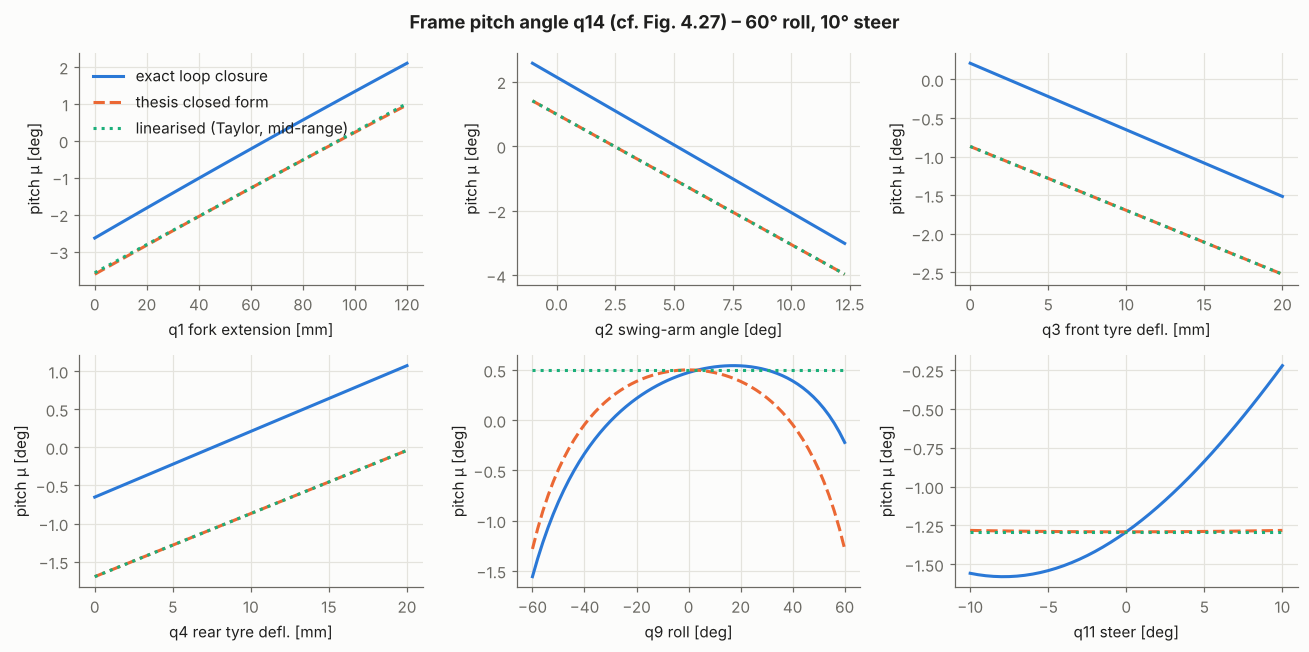

In [7]:
base = dict(q1=0.06, q2=0.5 * (p.q2_top + p.q2_bottom), q3=0.005, q4=0.005, q9=np.radians(60), q11=np.radians(10))
sweeps = {"q1": np.linspace(0, p.fork_travel, 41), "q2": np.linspace(p.q2_bottom, p.q2_top, 41),
          "q3": np.linspace(0, 0.02, 41), "q4": np.linspace(0, 0.02, 41),
          "q9": np.radians(np.linspace(-60, 60, 61)), "q11": np.radians(np.linspace(-10, 10, 41))}
unit = {"q1": (1e3, "q1 fork extension [mm]"), "q2": (deg(1), "q2 swing-arm angle [deg]"), "q3": (1e3, "q3 front tyre defl. [mm]"),
        "q4": (1e3, "q4 rear tyre defl. [mm]"), "q9": (deg(1), "q9 roll [deg]"), "q11": (deg(1), "q11 steer [deg]")}
names = ["q13", "q14", "q15", "q16", "q17", "q18", "q19"]

def sweep(var):
    xs = sweeps[var]; mid = 0.5 * (xs[0] + xs[-1])
    qm = make_q(**{**base, var: mid})
    vm, jm = kin.thesis_pose(qm)
    out = dict(x=xs, exact=[], thesis={n: [] for n in names}, lin={n: [] for n in names})
    for x in xs:
        q = make_q(**{**base, var: x})
        k = kin.config(q); out["exact"].append(k)
        v, _ = kin.thesis_pose(q)
        for n in names:
            out["thesis"][n].append(v[n]); out["lin"][n].append(vm[n] + jm[n] @ (q - qm))
    return out
S = {v: sweep(v) for v in sweeps}

def fig_compare(name, exact_fn, ylabel, scale=1.0, title=""):
    fig, axs = plt.subplots(2, 3, figsize=(12, 6)); axs = axs.ravel()
    for a, var in zip(axs, sweeps):
        s = S[var]; xs = s["x"] * unit[var][0]
        if exact_fn is not None:
            a.plot(xs, scale * np.array([exact_fn(k) for k in s["exact"]]), color=C[0], label="exact loop closure")
        a.plot(xs, scale * np.array(s["thesis"][name]), "--", color=C[1], label="thesis closed form")
        a.plot(xs, scale * np.array(s["lin"][name]), ":", color=C[2], label="linearised (Taylor, mid-range)")
        a.set_xlabel(unit[var][1]); a.set_ylabel(ylabel)
    axs[0].legend(); fig.suptitle(title, fontweight="bold"); plt.tight_layout()

fig_compare("q14", lambda k: k["mu"], "pitch μ [deg]", deg(1), "Frame pitch angle q14 (cf. Fig. 4.27) – 60° roll, 10° steer")

* In $q_1$, $q_2$ the three curves are parallel: the thesis' linearisation works, but (4.17) carries an **offset of about 1°** at this extreme
  roll/steer combination. It vanishes when either roll or steer is zero (see the roll and steer panels at 0° and the table further down).
* In $q_3$, $q_4$ the slopes differ slightly, (4.17) uses $1/\cos q_9$ for both tyres whereas the front one sees $\gamma_1$.
* Roll is strongly non-linear – the reason all coefficients are *scheduled over roll angle* in the thesis.
* Steer: the exact pitch varies by more than 1° over ±10° at 60° roll; (4.17) is flat.

### 4.8.2 / 4.8.3  x and z of the frame mass centre (Figs. 4.28, 4.29)
Eqs. (4.20), (4.21): position of *A* relative to the rear tyre point in the *D* frame. "Exact" is the same quantity from the exact loop closure.

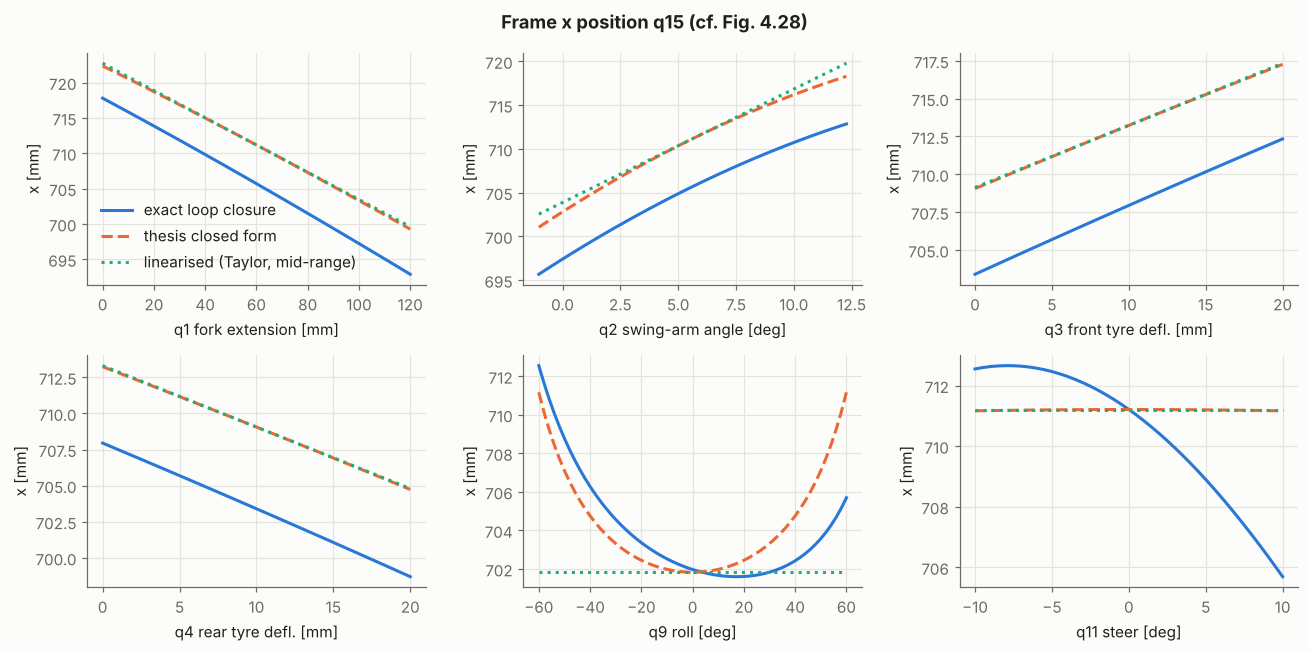

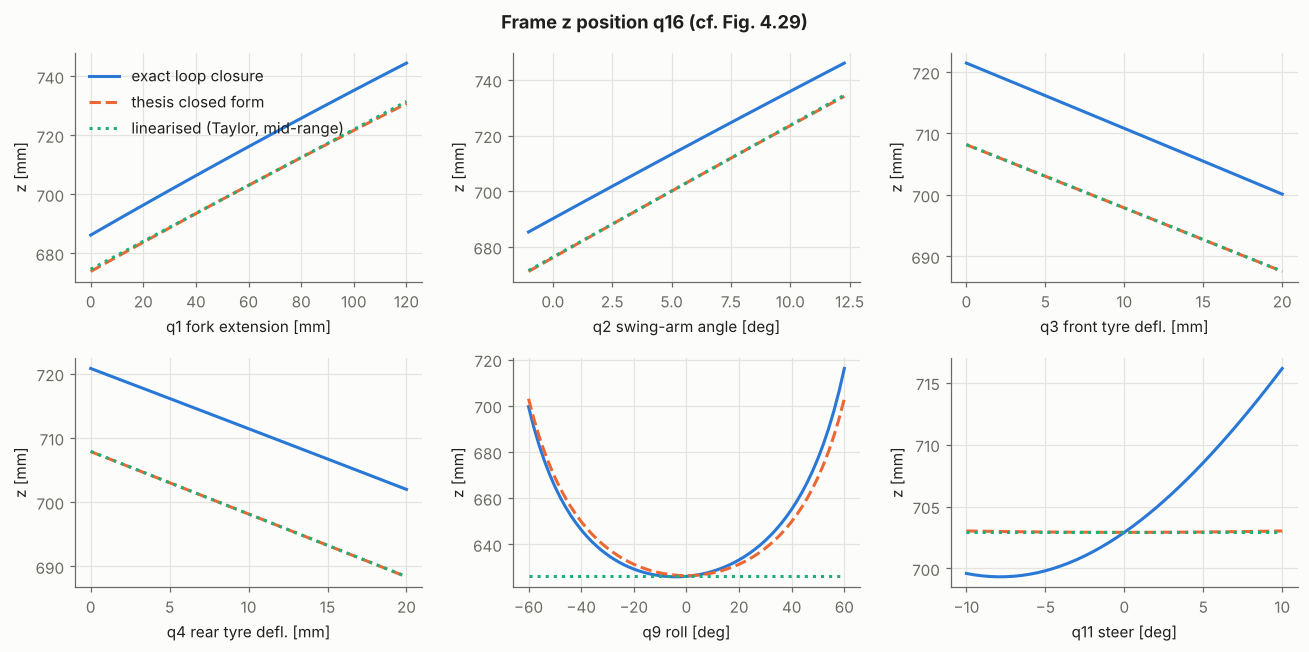

In [8]:
dcoord = lambda i: (lambda k: (k["R_D"].T @ (k["r_A"] - np.array([k["q"][6], 0, k["q"][7]])))[i])
fig_compare("q15", dcoord(0), "x [mm]", 1e3, "Frame x position q15 (cf. Fig. 4.28)")
fig_compare("q16", dcoord(1), "z [mm]", 1e3, "Frame z position q16 (cf. Fig. 4.29)")

### 4.8.4 / 4.8.5  Wheelbase $q_{18}$ and trail $q_{19}$
The closed forms measure both in the plane of the frame. The exact values are taken on the ground between the true contact points
(wheelbase: $\hat m_1$ component; trail: distance from the steering-axis/ground intersection back to the contact point along the wheel heading $\hat h_1$).

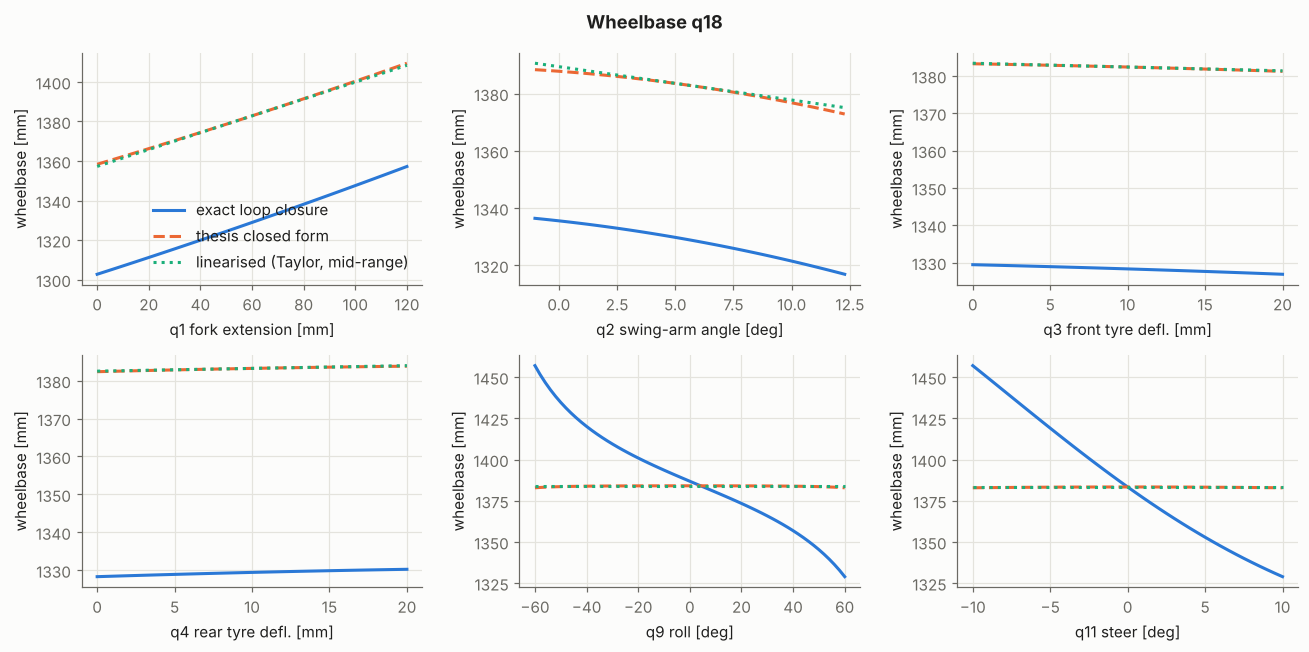

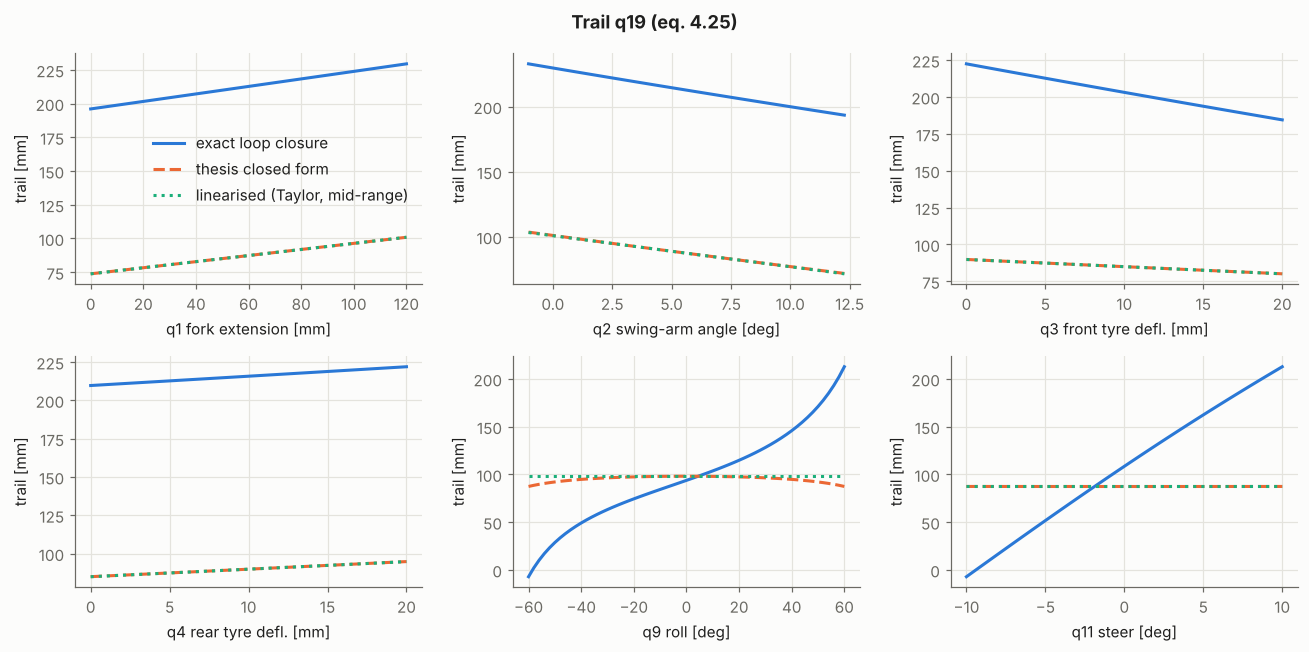

In [9]:
fig_compare("q18", lambda k: k["wheelbase_x"], "wheelbase [mm]", 1e3, "Wheelbase q18")
fig_compare("q19", lambda k: k["trail"], "trail [mm]", 1e3, "Trail q19 (eq. 4.25)")

Eq. (4.25) gives the trail of the upright bike; it captures the dependence on pitch (through $q_1$, $q_2$) well. The exact ground trail additionally
depends strongly on roll **and** steer because the contact point migrates over the crown – at 60° roll it changes from about 0 to 210 mm over ±10° of steer.
This matters once tyre forces act at the contact point (the dynamics code uses the exact contact point).

### 4.8.6 / 4.8.7  Frame yaw $q_{13}$ and lateral position $q_{17}$ (Figs. 4.31, 4.32)
The thesis measures yaw $\psi$ along the line through both contact points and gives the frame a small yaw $q_{13}=y/q_{18}$ relative to it.
The exact equivalent is the angle between the ground trace of the frame plane and the line joining the true contact points.

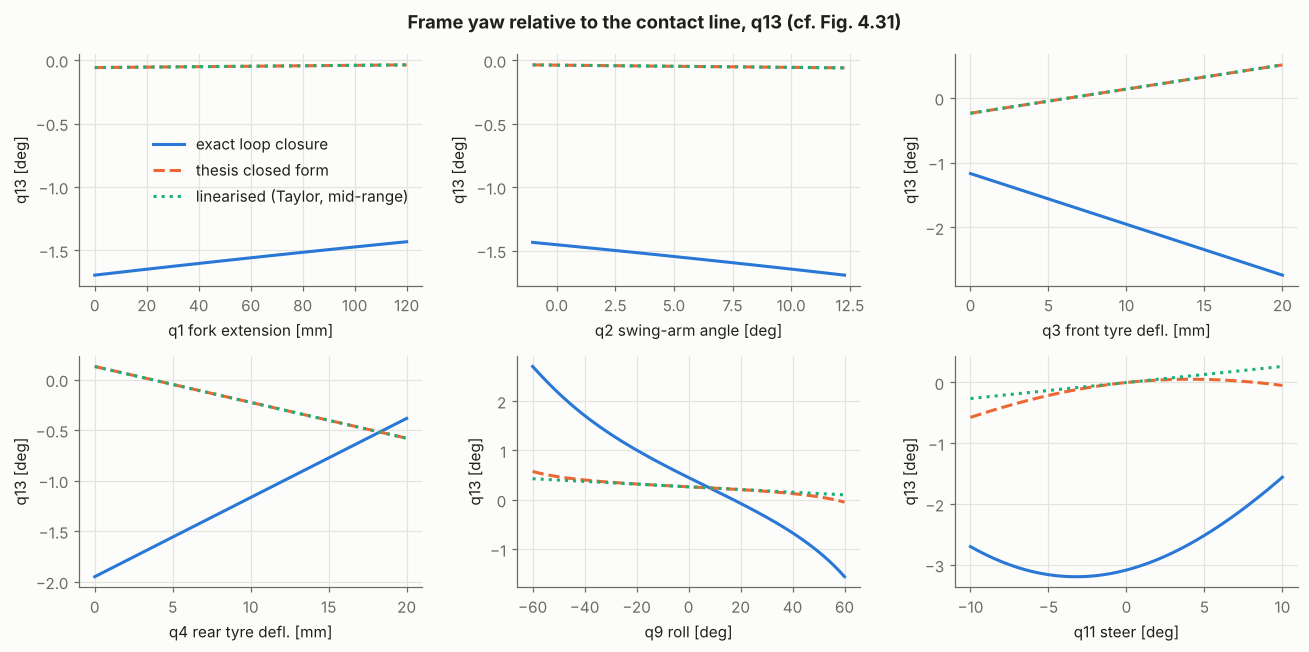

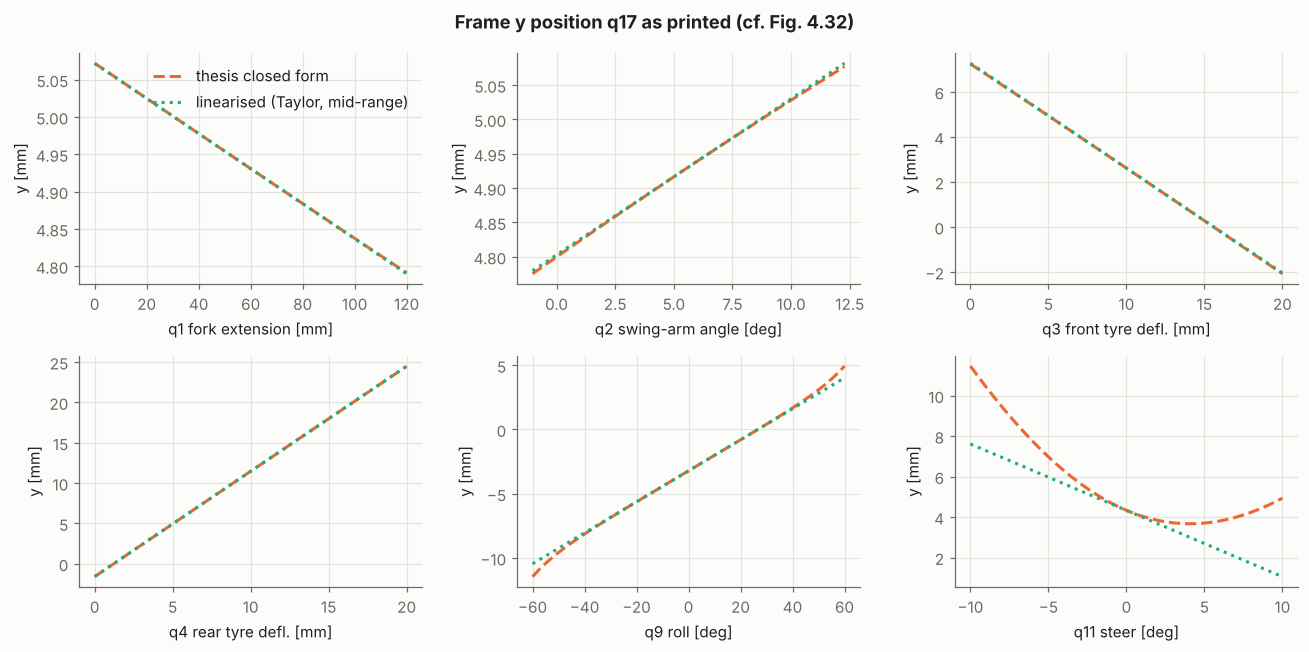

In [10]:
fig_compare("q13", lambda k: k["q13_exact"], "q13 [deg]", deg(1), "Frame yaw relative to the contact line, q13 (cf. Fig. 4.31)")
fig_compare("q17", None, "y [mm]", 1e3, "Frame y position q17 as printed (cf. Fig. 4.32)")

In [11]:
print(" roll steer |  mu (4.17)  mu exact |  q13 thesis  q13 exact   [deg]")
for r in (0, 30, 60):
    for st in (0, 5, 10):
        q = make_q(q1=0.08, q2=0.15, q3=0.005, q4=0.005, q9=np.radians(r), q11=np.radians(st))
        k = kin.config(q); v, _ = kin.thesis_pose(q)
        print(f"  {r:3d}  {st:3d}  |  {deg(v['q14']):8.3f}  {deg(k['mu']):8.3f}  |  {deg(v['q13']):8.3f}  {deg(k['q13_exact']):8.3f}")

 roll steer |  mu (4.17)  mu exact |  q13 thesis  q13 exact   [deg]
    0    0  |     0.056     0.056  |     0.000     0.000
    0    5  |     0.058     0.052  |     0.131     0.223
    0   10  |     0.065     0.040  |     0.262     0.437
   30    0  |    -0.219    -0.219  |     0.000    -1.026
   30    5  |    -0.217    -0.085  |     0.108    -0.734
   30   10  |    -0.210     0.058  |     0.169    -0.366
   60    0  |    -1.721    -1.721  |     0.000    -3.076
   60    5  |    -1.719    -1.279  |     0.050    -2.519
   60   10  |    -1.712    -0.673  |    -0.050    -1.573


**Findings on $q_{13}$.** Upright, the exact value is $a_n\sin\delta/W$ reduced by the crown-radius shift (≈0.44° at 10° steer); the printed
expression keeps only the fork-offset term $Q_x\sin\delta$ after setting $\gamma_1\approx q_9$ (0.26°). With roll, the largest contribution is the
different crown radius of the two tyres, $(\rho_r-\rho_f)\tan\gamma/W$ ≈ 3° at 60°, which the printed form does not contain.
All of these are small angles, but they are of the same order as tyre slip angles, so the definition matters for Chapter 5.

**Consequence for the dynamics code (notebook 4).** The multibody model uses the exact loop closure and defines the yaw angle $q_{10}$ as the heading
of the frame/rear-wheel plane (consistent with Table 4.4, where *A* differs from *D* by the pitch rotation only). Then $q_{13}\equiv0$,
$q_{17}\equiv0$ and the contact points lie wherever the geometry puts them. The thesis' closed-form pitch (4.17) remains selectable
(`pitch_model="thesis"`).

## Scheduling over roll (end of 4.8.8)
The linearisation coefficients depend strongly on roll; the thesis tabulates them at initialisation and interpolates at run time.
Here they are cheap enough to evaluate at every step, the plot shows what such a table contains.

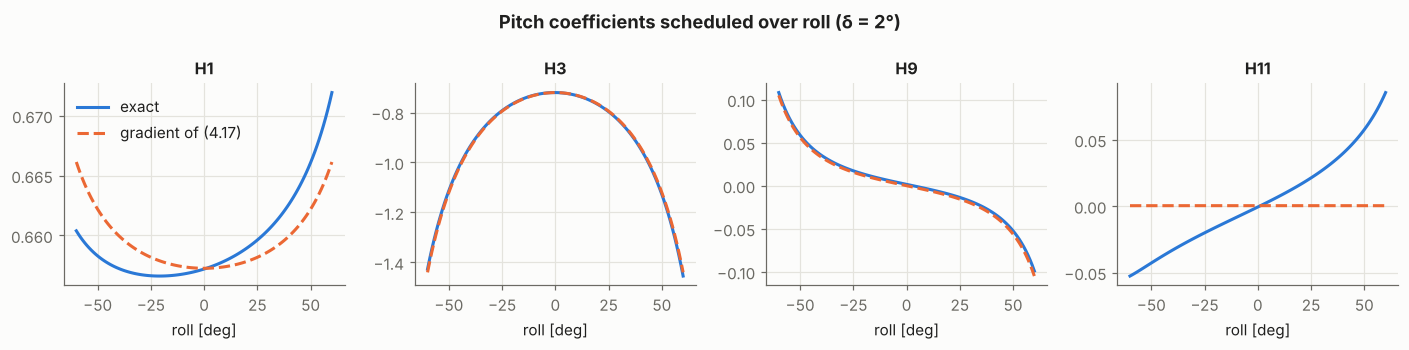

In [12]:
rolls = np.radians(np.linspace(-60, 60, 121))
Hx = np.array([kin.pitch(make_q(q1=0.08, q2=0.15, q3=0.005, q4=0.006, q9=r, q11=np.radians(2)), model="exact")[1] for r in rolls])
Ht = np.array([kin.pitch(make_q(q1=0.08, q2=0.15, q3=0.005, q4=0.006, q9=r, q11=np.radians(2)), model="thesis")[1] for r in rolls])
fig, axs = plt.subplots(1, 4, figsize=(13, 3.2))
for a, (i, n) in zip(axs, [(0, "H1"), (2, "H3"), (8, "H9"), (10, "H11")]):
    a.plot(deg(rolls), Hx[:, i], color=C[0], label="exact"); a.plot(deg(rolls), Ht[:, i], "--", color=C[1], label="gradient of (4.17)")
    a.set_title(n); a.set_xlabel("roll [deg]")
axs[0].legend(); fig.suptitle("Pitch coefficients scheduled over roll (δ = 2°)", fontweight="bold"); plt.tight_layout()